# TP3. Polynômes et fonctions

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp3-polynomes-fonctions/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : évaluation naïve

Écrivez `evaluer_naif(P, x)` qui calcule $P(x)$ en suivant la définition, avec une
puissance par terme.

**Résultat attendu :** `evaluer_naif([2, 3, 0, 5], 2)` vaut `48`, car
$2 + 6 + 40 = 48$.


In [1]:
# votre réponse ici
def evaluer_naif(coefs: list, x: float) -> float:
    puis = 0
    valeur = 0
    for coef in coefs:
        valeur += coef * x**puis
        puis += 1
    return valeur

assert evaluer_naif([2, 3, 0, 5], 2) == 48
assert evaluer_naif([1, 2, 3, 4, 5, 6, 7], 1) == 1+2+3+4+5+6+7
assert evaluer_naif([9, 5, 0, 3, 6], 0) == 9

## Exercice 2.1 : Horner

Écrivez `evaluer(P, x)` par le schéma de Horner, et vérifiez qu'elle donne le même
résultat que la version naïve sur plusieurs points.

**Résultat attendu :** les deux fonctions coïncident, et Horner est plus rapide sur un
polynôme de degré élevé.


In [2]:
# votre réponse ici
def evaluer(P, x):
    total = 0
    for coef in reversed(P):
        total = total * x + coef
    return total

assert evaluer([2, 3, 0, 5], 2) == evaluer_naif([2, 3, 0, 5], 2)
assert evaluer([1, 2, 3, 4, 5, 6, 7], 1) == evaluer_naif([1, 2, 3, 4, 5, 6, 7], 1)
assert evaluer([9, 5, 0, 3, 6], 0) == evaluer_naif([9, 5, 0, 3, 6], 0)

## Exercice 2.2 : mesurer, et se méfier de ses prévisions

Construisez des polynômes dont tous les coefficients valent 1, de degrés 1 000, 5 000
et 20 000, et comparez le temps des deux méthodes en `x = 1.0001`. Avant de lancer la
mesure, écrivez votre prévision : de combien Horner devrait-il être plus rapide ?

**Résultat attendu :** un rapport d'environ 2, **constant** quand le degré augmente.
Ce n'est probablement pas ce que vous aviez prévu.


In [3]:
# votre réponse ici

import time

def duree(fonction, argument1, argument2):
    """Renvoie le temps d'exécution de fonction(argument1, argument2), en secondes."""
    debut = time.perf_counter()
    fonction(argument1, argument2)
    return time.perf_counter() - debut

deg1000 = [1]*1000
deg5000 = [1]*5000
deg20000 = [1]*20000

print("Degré 1 000 -> naif : " + str(duree(evaluer_naif, deg1000, 1.0001)) + "s ; Horner : " + str(duree(evaluer, deg1000, 1.0001)) + "s .")

print("Degré 5 000 -> naif : " + str(duree(evaluer_naif, deg5000, 1.0001)) + "s ; Horner : " + str(duree(evaluer, deg5000, 1.0001)) + "s .")

print("Degré 20 000 -> naif : " + str(duree(evaluer_naif, deg20000, 1.0001)) + "s ; Horner : " + str(duree(evaluer, deg20000, 1.0001)) + "s .")


Degré 1 000 -> naif : 0.00025999999999992696s ; Horner : 9.999999999976694e-05s .
Degré 5 000 -> naif : 0.0015199999999992997s ; Horner : 0.00048000000000048004s .
Degré 20 000 -> naif : 0.004819999999999602s ; Horner : 0.0017599999999999838s .


## Exercice 2.3 : le cas où l'écart explose vraiment

Refaites la mesure en évaluant en `x = 3`, un **entier**, sur des degrés 200, 400
et 800. Le rapport reste-t-il constant ?

**Résultat attendu :** cette fois le rapport grandit avec le degré, d'environ 4 à
environ 6.


In [4]:
# votre réponse ici
# votre réponse ici

import time

def duree(fonction, argument1, argument2):
    """Renvoie le temps d'exécution de fonction(argument1, argument2), en secondes."""
    debut = time.perf_counter()
    fonction(argument1, argument2)
    return time.perf_counter() - debut

deg200 = [1]*200
deg400 = [1]*400
deg800 = [1]*800

naif = duree(evaluer_naif, deg200, 3)
horner = duree(evaluer, deg200, 3)
print("Degré 200 -> naif : " + str(naif) + "s ; Horner : " + str(horner) + "s . Rapport : " + str(naif/horner))

naif = duree(evaluer_naif, deg400, 3)
horner = duree(evaluer, deg400, 3)
print("Degré 400 -> naif : " + str(naif) + "s ; Horner : " + str(horner) + "s . Rapport : " + str(naif/horner))

naif = duree(evaluer_naif, deg800, 3)
horner = duree(evaluer, deg800, 3)
print("Degré 800 -> naif : " + str(naif) + "s ; Horner : " + str(horner) + "s . Rapport : " + str(naif/horner))

Degré 200 -> naif : 0.00020000000000042206s ; Horner : 6.000000000039307e-05s . Rapport : 3.33333333331853
Degré 400 -> naif : 0.000460000000000349s ; Horner : 9.999999999976694e-05s . Rapport : 4.6000000000142105
Degré 800 -> naif : 0.001280000000000392s ; Horner : 0.00019999999999953388s . Rapport : 6.400000000016876


## Exercice 3.1 : la dérivée

Écrivez `deriver(P)` qui renvoie la liste des coefficients du polynôme dérivé.

**Résultat attendu :** `deriver([2, 3, 0, 5])` vaut `[3, 0, 15]`, c'est-à-dire
$3 + 15x^{2}$.


In [5]:
# votre réponse ici
def deriver(P):
    resultat = []
    for i in range(1, len(P)):
        resultat.append(i*P[i])
    return resultat

assert deriver([2, 3, 0, 5]) == [3, 0, 15]
assert deriver([9999, 3, 0, 5]) == [3, 0, 15]
assert deriver([2, 3, 0, 5, 1]) == [3, 0, 15, 4]

## Exercice 4.1 : dichotomie

Écrivez `dichotomie(f, a, b, tolerance)` qui renvoie une racine de `f` entre `a` et
`b`. Appliquez-la à $x^{2} - 2$ sur $[0, 2]$.

**Résultat attendu :** une valeur proche de $\sqrt{2} \approx 1{,}414214$.


In [6]:
# votre réponse ici
def dichotomie(f, a, b, tolerance):
    """Renvoie une racine de f situé entre a et b"""
    debut = a
    fin = b
    milieu = (a+b)/2
    compteur = 0
    while not (-tolerance <= f(milieu) and f(milieu) <= tolerance) and compteur < 10000:
        if f(milieu) > 0 and f(debut) < 0 or f(milieu) < 0 and f(debut) > 0:
            fin = milieu
        elif f(milieu) > 0 and f(fin) < 0 or f(milieu) < 0 and f(fin) > 0:
            debut = milieu
        else:
            print("AAA")
        milieu = (debut + fin) / 2
        compteur += 1
    if compteur >= 10000:
        print("Boucle infini?")
    return milieu

def f(x):
    return x*x - 2

print(dichotomie(f, 0, 2, 1E-12))

1.4142135623733338


## Exercice 4.2 : Newton sur un polynôme

Écrivez `newton(P, depart, tolerance)` qui cherche une racine du polynôme `P` en
utilisant `evaluer` et `deriver`. Appliquez-la à $x^{3} - 2x - 5$, en partant de 2.

**Résultat attendu :** environ `2.0945515`, atteint en cinq tours ou moins.


In [18]:
# votre réponse ici
def newton(P, depart, tolerance=1e-12, tours_max=100):
    """Racine du polynôme P par la méthode de Newton, à partir de depart."""
    derivee = deriver(P)
    x = float(depart)
    for tour in range(tours_max):
        valeur = evaluer(P, x)
        pente = evaluer(derivee, x)
        if pente == 0:
            raise ZeroDivisionError("tangente horizontale, Newton ne peut pas continuer")
        suivant = x - valeur / pente
        if abs(suivant - x) <= tolerance * max(1.0, abs(suivant)):
            return suivant, tour + 1
        x = suivant
    raise RuntimeError("pas de convergence en {} tours".format(tours_max))

# x^3 - 2x - 5
Q = [-5, -2, 0, 1]
racine, tours = newton(Q, 2)
print(racine, "en", tours, "tours")
print(abs(evaluer(Q, racine)) < 1e-10)

2.0945514815423265 en 5 tours
True


## Exercice 4.3 : faire échouer Newton

Appliquez `newton` au polynôme $x^{3} - 2x + 2$, c'est-à-dire `[2, -2, 0, 1]`, en
partant de `0`. Affichez le trajet des premiers itérés pour comprendre ce qui se passe.

**Résultat attendu :** aucune convergence, et un trajet qui alterne entre `0` et `1`
indéfiniment.


In [30]:
# votre réponse ici

def newton_trajet(P, depart, tolerance=1e-12, tours_max=100):
    """Racine du polynôme P par la méthode de Newton, à partir de depart."""
    derivee = deriver(P)
    x = float(depart)
    trajet = [x]
    for tour in range(tours_max):
        valeur = evaluer(P, x)
        pente = evaluer(derivee, x)
        if pente == 0:
            raise ZeroDivisionError("tangente horizontale, Newton ne peut pas continuer")
        suivant = x - valeur / pente
        if abs(suivant - x) <= tolerance * max(1.0, abs(suivant)):
            return suivant, tour + 1
        x = suivant
        trajet.append(x)
    return trajet
    #raise RuntimeError("pas de convergence en {} tours".format(tours_max))

print(newton_trajet([2, 2, 0, 1], 0, 1e-12, 8))

(-1.122706478670217, 9)


## Exercice 4.4 : le prix d'un mauvais point de départ

Reprenez $x^{3} - 2x - 5$ et comparez le nombre de tours de `newton` en partant
de `2`, puis de `0`.

**Résultat attendu :** cinq tours depuis `2`, une vingtaine depuis `0`.


In [26]:
# votre réponse ici
print(f"newton(Q, 2) : {newton(Q,2)[1]} tours")
print(f"newton(Q, 2) : {newton(Q,0)[1]} tours")

newton(Q, 2) : 5 tours
newton(Q, 2) : 20 tours


## Exercice 5.1 : lire le graphique

Sur le tracé, repérez la racine trouvée par Newton. Combien de fois la courbe
coupe-t-elle l'axe des abscisses ? Ce polynôme est de degré 3 : que dire de ses autres
racines ?


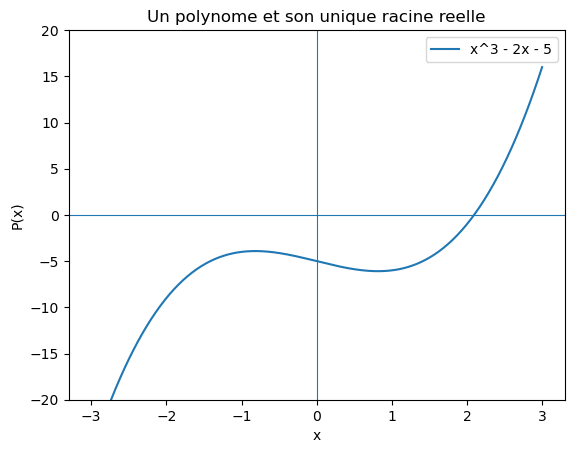

In [27]:
# votre réponse ici
import matplotlib.pyplot as plt

Q = [-5, -2, 0, 1]          # x^3 - 2x - 5
xs = [i / 100 for i in range(-300, 301)]
ys = [evaluer(Q, x) for x in xs]

plt.figure()
plt.plot(xs, ys, label="x^3 - 2x - 5")
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.ylim(-20, 20)
plt.xlabel("x")
plt.ylabel("P(x)")
plt.legend()
plt.title("Un polynome et son unique racine reelle")
plt.show()

# La courbe coupe l'axe des abscisses une fois. Les 2 autres racines sont imaginaires.

## Exercice 6.1 : somme et produit

Écrivez `somme(P, Q)` et `produit_poly(P, Q)`. Attention, les deux listes n'ont pas
forcément la même longueur.

**Résultat attendu :** `produit_poly([1, 1], [1, 1])` vaut `[1, 2, 1]`, c'est-à-dire
$(1 + x)^{2} = 1 + 2x + x^{2}$, et `produit_poly([-1, 1], [1, 1])` vaut
`[-1, 0, 1]`, l'identité $(x - 1)(x + 1) = x^{2} - 1$.


In [11]:
# votre réponse ici


## Exercice 6.2 : le triangle de Pascal, par les polynômes

Calculez $(1 + x)^{10}$ en multipliant dix fois `[1, 1]` par lui-même. Que
reconnaissez-vous dans la liste obtenue ?

**Résultat attendu :** `[1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]`.


In [12]:
# votre réponse ici


## Exercice 7.1 : trouver le meilleur pas

Écrivez `derivee_avant(f, x, h)` et `derivee_centree(f, x, h)`. Calculez l'erreur de
chacune sur $\sin$ en $x = 1$, dont la dérivée exacte est $\cos 1$, pour
`h` valant $10^{-1}, 10^{-2}, 10^{-4}, 10^{-6}, 10^{-8}, 10^{-10}, 10^{-12}$.

**Résultat attendu :** l'erreur diminue puis **remonte**. Le meilleur pas est de
l'ordre de $10^{-8}$ pour la formule avant, $10^{-6}$ pour la formule centrée,
et à $h = 10^{-12}$ l'erreur est remontée de quatre à six ordres de grandeur
par rapport à ce meilleur pas.


In [13]:
# votre réponse ici


## Exercice 8.1 : les trois méthodes

Écrivez `rectangles(f, a, b, n)`, `trapezes(f, a, b, n)` et `simpson(f, a, b, n)`.
Testez-les sur $\int_0^1 x^{2}\,dx = 1/3$ pour `n` valant 10, 100 et 1000.

**Résultat attendu :** l'erreur des rectangles est divisée par 10 quand `n` est
multiplié par 10, celle des trapèzes par 100, et Simpson donne le résultat exact, à
un arrondi de $10^{-17}$ près.


In [14]:
# votre réponse ici


## Exercice 8.2 : calculer π

On a $\int_0^1 \frac{4}{1 + x^{2}}\,dx = \pi$. Calculez cette intégrale par les
trapèzes et par Simpson avec `n = 1000`, et comparez à `math.pi`.

**Résultat attendu :** une erreur de l'ordre de $10^{-7}$ pour les trapèzes, et
un résultat indistinguable de `math.pi` pour Simpson.


In [15]:
# votre réponse ici
